# Curated and Automatically Reconstructed GEMs

<!-- launch-badges -->
[![KTH JupyterHub](https://img.shields.io/badge/launch-KTH%20JupyterHub-F37626?logo=jupyter&logoColor=white)](https://nbserv.duckdns.org/hub/user-redirect/git-pull?repo=https://github.com/statisticalbiotechnology/dsbook&urlpath=lab/tree/dsbook/dsbook/network/gem_ecoli.ipynb&branch=main)
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/statisticalbiotechnology/dsbook/blob/main/dsbook/network/gem_ecoli.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/statisticalbiotechnology/dsbook/main?labpath=dsbook/network/gem_ecoli.ipynb)

## Where do GEMs come from?

In the previous chapter we wrote down the stoichiometric matrix of a five-metabolite toy model by hand. A genome-scale model has thousands of rows and columns, and the question of where they come from matters a lot for how far we can trust the predictions.

The classical route is **bottom-up reconstruction**. A draft network is assembled from the genome annotation and pathway databases, and then curated reaction by reaction against the biochemical literature and against experiments: Is the reaction reversible? Which cofactor does the enzyme use? Can the model grow on the carbon sources the organism is known to grow on? For *E. coli* this process has gone on for more than two decades and through several model generations, culminating in *i*ML1515 ([Monk et al. 2017](https://doi.org/10.1038/nbt.3956)). Curating a model this way takes person-years of work, so it is only done for a handful of well-studied organisms.

For the many thousands of bacteria that are sequenced but barely studied, one needs an automatic route. [CarveMe](https://github.com/cdanielmachado/carveme) ([Machado et al. 2018](https://doi.org/10.1093/nar/gky537)) takes a **top-down** approach. It starts from a manually curated **universal model**, a single bacterial GEM containing essentially every reaction known from the BiGG database, already mass- and charge-balanced and with a generic biomass reaction. Given the annotated protein sequences of a new genome, CarveMe aligns them against the genes of the universal model and scores each reaction by how well it is supported by the genome. It then "carves" an organism-specific model out of the universal one by solving a mixed-integer linear program. The program keeps reactions with strong genomic evidence, removes reactions without it, and requires that the result is still a connected network able to produce biomass. Making a new model this way takes minutes rather than years. The authors used the tool to build a [collection of 5,587 models](https://github.com/cdanielmachado/embl_gems), one for every reference bacterial genome in RefSeq.

When the previous chapter said that predicted essentiality agrees with experimental knockout screens for roughly 90% of the genes in *E. coli*, it was referring to the curated models. In this chapter we take the same organism, *E. coli* K-12 MG1655, and compare its curated model with the one CarveMe built automatically from its genome. Because *E. coli* is so well studied, we can test both models against experimental data. This tells us something about how much to trust the automatic models of organisms where no such test is possible.

## Loading the models

We use [COBRApy](https://opencobra.github.io/cobrapy/), the standard Python package for constraint-based modeling. It reads models in the SBML format and provides FBA, FVA and gene deletion as ready-made functions.

In [1]:
import importlib.util, sys
def _has(pkg): return importlib.util.find_spec(pkg) is not None
if not _has("cobra"):
    %pip install -q "cobra"

We download four files and cache them under `dsbook/data/`. They are the curated model *i*ML1515 from the [BiGG database](http://bigg.ucsd.edu/models/iML1515), the CarveMe model of the same strain from the EMBL GEMs collection, NCBI's feature table for the genome (to translate gene identifiers between the two models), and the experimental essentiality data described further down.

In [2]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cobra

IN_COLAB = 'google.colab' in sys.modules
data_dir = "dsbook/dsbook/data/" if IN_COLAB else "../data/"
os.makedirs(data_dir, exist_ok=True)

embl_gems = "https://github.com/cdanielmachado/embl_gems/raw/master/models/"
urls = {
    "iML1515.xml.gz": "https://bigg.ucsd.edu/static/models/iML1515.xml.gz",
    "Escherichia_coli_str_K_12_substr_MG1655.xml.gz":
        embl_gems + "e/escherichia/Escherichia_coli_str_K_12_substr_MG1655.xml.gz",
    "Ecoli_MG1655_feature_table.txt.gz":
        "https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/000/005/845/GCF_000005845.2_ASM584v2/"
        "GCF_000005845.2_ASM584v2_feature_table.txt.gz",
    "PECData.dat": "https://shigen.nig.ac.jp/ecoli/pec/download/files/PECData.dat",
}

def fetch(name):
    path = data_dir + name
    if not os.path.exists(path):
        print(f"Downloading {name} ...")
        urllib.request.urlretrieve(urls[name], path)
    return path

curated = cobra.io.read_sbml_model(fetch("iML1515.xml.gz"))
carved = cobra.io.read_sbml_model(fetch("Escherichia_coli_str_K_12_substr_MG1655.xml.gz"))

pd.DataFrame({
    name: {"reactions": len(m.reactions), "metabolites": len(m.metabolites),
           "genes": len(m.genes)}
    for name, m in [("curated (iML1515)", curated), ("CarveMe", carved)]
})

,curated (iML1515),CarveMe
reactions,2712,2759
metabolites,1877,1722
genes,1516,1554


The two models are about the same size. Inside, each model is the same kind of object as our toy model: a stoichiometric matrix, bounds, an objective, and GPR rules. COBRApy builds $S$ for us:

In [3]:
from cobra.util.array import create_stoichiometric_matrix

S = create_stoichiometric_matrix(curated)
print(f"S has shape {S.shape}; {np.count_nonzero(S) / S.size:.2%} of its entries are nonzero")

pgi = curated.reactions.get_by_id("PGI")
print(pgi.name, ":", pgi.reaction, "| GPR:", pgi.gene_reaction_rule)

S has shape (1877, 2712); 0.21% of its entries are nonzero
Glucose-6-phosphate isomerase : g6p_c <=> f6p_c | GPR: b4025


As expected, the matrix is extremely sparse. Each reaction carries a GPR rule over gene identifiers. *i*ML1515 uses the classical *E. coli* locus tags (b-numbers, e.g. `b4025` for phosphoglucose isomerase). CarveMe models, built from the RefSeq proteome, use protein accessions such as `NP_418449_1` instead. We translate them using NCBI's feature table for the genome:

In [4]:
features = pd.read_csv(fetch("Ecoli_MG1655_feature_table.txt.gz"), sep="\t")
cds = features[features["# feature"] == "CDS"]
protein_to_locus = dict(zip(cds["product_accession"].str.replace(".", "_"), cds["locus_tag"]))

carved_genes = {protein_to_locus.get(g.id) for g in carved.genes}
curated_genes = {g.id for g in curated.genes}
print(f"{len(carved.genes)} CarveMe genes, {len(carved_genes - {None})} mapped to locus tags")
print(f"genes in both models: {len(curated_genes & carved_genes)}, "
      f"only curated: {len(curated_genes - carved_genes)}, "
      f"only CarveMe: {len(carved_genes - curated_genes)}")

1554 CarveMe genes, 1550 mapped to locus tags
genes in both models: 1312, only curated: 204, only CarveMe: 239


CarveMe's universal model uses the same BiGG reaction identifiers as *i*ML1515, so we can compare the reaction contents of the two models directly:

In [5]:
curated_rxns = {r.id for r in curated.reactions}
carved_rxns = {r.id for r in carved.reactions}
print(f"reactions in both models: {len(curated_rxns & carved_rxns)}, "
      f"only curated: {len(curated_rxns - carved_rxns)}, "
      f"only CarveMe: {len(carved_rxns - curated_rxns)}")

reactions in both models: 2238, only curated: 474, only CarveMe: 521


Roughly four out of five reactions are shared. Each model also has several hundred reactions the other lacks, and those differences can matter for predictions.

## Growth on glucose, with and without oxygen

Before we can simulate anything, we need to specify the environment. In COBRApy the **medium** is a dictionary that maps each exchange reaction to its maximal uptake rate. *i*ML1515 ships with M9 minimal medium with glucose as the only carbon source. The CarveMe models in the collection come with all exchange reactions open, so we give the carved model the same medium (omitting a few trace elements that it has no exchange reactions for).

In [6]:
m9_glucose = dict(curated.medium)
carved.medium = {ex: rate for ex, rate in m9_glucose.items() if ex in carved.reactions}

def growth(model, **changes):
    """Optimal growth rate after changing the uptake bounds of some exchange reactions."""
    with model:  # all changes are reverted when the block ends
        medium = model.medium
        medium.update(changes)
        model.medium = medium
        return model.slim_optimize(error_value=0.0)

pd.DataFrame({
    "aerobic": {"curated": growth(curated), "CarveMe": growth(carved)},
    "anaerobic": {"curated": growth(curated, EX_o2_e=0.0),
                  "CarveMe": growth(carved, EX_o2_e=0.0)},
}).round(3)

,aerobic,anaerobic
curated,0.877,0.158
CarveMe,1.009,0.000


The objective value is a growth rate in h⁻¹. Aerobically, the curated model predicts a growth rate within the roughly 0.7–0.9 h⁻¹ measured for *E. coli* in glucose minimal medium, while the CarveMe model predicts a somewhat faster growth of about 1 h⁻¹. Without oxygen, the curated model grows more slowly, as real *E. coli* does by fermentation. The CarveMe model does not grow at all, even though *E. coli* is a facultative anaerobe.

To find out why, we can test the biomass components one at a time. For each metabolite consumed by the biomass reaction, we add a temporary *demand* reaction that drains it, make that the objective, and check whether the network can produce it without oxygen:

In [7]:
def unproducible_biomass_components(model, biomass_id, **changes):
    blocked = []
    with model:
        medium = model.medium
        medium.update(changes)
        model.medium = medium
        for met, coef in model.reactions.get_by_id(biomass_id).metabolites.items():
            if coef < 0:  # consumed by biomass
                with model:
                    model.objective = model.add_boundary(met, type="demand")
                    if model.slim_optimize(error_value=0.0) < 1e-6:
                        blocked.append(met.id)
    return blocked

unproducible_biomass_components(carved, "Growth", EX_o2_e=0.0)

['pydx5p_c']

Only one component is missing: pyridoxal 5'-phosphate (`pydx5p_c`), the active form of vitamin B6. Let us look at the reactions that produce it in each model:

In [8]:
for name, model in [("curated", curated), ("CarveMe", carved)]:
    print(name)
    for r in model.metabolites.get_by_id("pydx5p_c").reactions:
        if r.get_coefficient("pydx5p_c") > 0 and not r.id.startswith(("BIOMASS", "Growth")):
            print(f"  {r.id:10s} {r.reaction:45s} GPR: {r.gene_reaction_rule or '(none)'}")

curated
  PYDXK      atp_c + pydx_c --> adp_c + h_c + pydx5p_c     GPR: b2418 or b1636
  PDX5POi    o2_c + pdx5p_c --> h2o2_c + pydx5p_c          GPR: b1638
  PDX5PO2    nad_c + pdx5p_c --> h_c + nadh_c + pydx5p_c   GPR: (none)
  PYAM5PO    h2o_c + o2_c + pyam5p_c --> h2o2_c + nh4_c + pydx5p_c GPR: b1638
CarveMe
  PYDXK      atp_c + pydx_c --> adp_c + h_c + pydx5p_c     GPR: NP_416153_1 or NP_416913_1
  PYAM5PO    h2o_c + o2_c + pyam5p_c --> h2o2_c + nh4_c + pydx5p_c GPR: NP_416155_1 or NP_418588_1
  PDX5POi    o2_c + pdx5p_c --> h2o2_c + pydx5p_c          GPR: NP_416155_1 or NP_418588_1


In both models the last step of the canonical pathway, `PDX5POi`, is catalyzed by an oxidase that uses molecular oxygen. *i*ML1515 also contains `PDX5PO2`, an NAD⁺-dependent version of the same step that has **no gene associated with it**. The curators added it because *E. coli* is known to grow anaerobically, so the cell must have some way to make vitamin B6 without oxygen, even though the responsible enzyme has not been identified. CarveMe works only from genomic evidence, so a reaction without a gene cannot get into the carved model.

This is the main tradeoff between the two approaches. A curated model contains experimental knowledge that is not in the genome sequence. An automatic model contains only what the genome supports. CarveMe can partly close such gaps if the user specifies the media the organism is known to grow on: it then *gap-fills* the model by adding the fewest universal-model reactions needed to grow on those media. The models in the collection were built without such information.

## Testing essentiality predictions against knockout data

Now for the test the previous chapter promised. As experimental ground truth we use the [PEC database](https://shigen.nig.ac.jp/ecoli/pec/) (Profiling of *E. coli* Chromosome). It classifies every *E. coli* K-12 gene as essential or non-essential based on systematic deletion studies, most importantly the [Keio collection](https://doi.org/10.1038/msb4100050) of single-gene knockouts. Genes in which no viable knockout could be obtained on rich (LB) medium are classified as essential.

In [9]:
pec = pd.read_csv(fetch("PECData.dat"), sep="\t")
pec["locus"] = pec["Alternative name"].str.extract(r"(b\d{4})", expand=False)
pec["class"] = pec.filter(like="Class").iloc[:, 0].map({1: "essential", 2: "non-essential"})
pec = pec.dropna(subset=["locus", "class"])
pec = pec.drop_duplicates(subset="locus")
observed_essential = pec.set_index("locus")["class"].eq("essential")
observed_essential.value_counts()

class
False    4172
True      302
Name: count, dtype: int64

About 300 of the 4,500 genes are essential. Most of them are not metabolic: they code for ribosomal proteins, the replication machinery, cell division and so on. A metabolic model cannot say anything about those genes, so we only evaluate the genes that each model contains.

The experiment was done on rich medium, so we have to simulate rich medium too. LB is a poorly defined mixture of yeast extract and peptone, and a simple approximation is to let the model take up every compound it has an exchange reaction for. We then delete each gene in turn with `single_gene_deletion`, which applies the GPR logic from the previous chapter to the whole model. Since the experiment only records whether a mutant grows, we call a gene essential when its knockout reduces the predicted growth to less than 5% of the wild type.

In [10]:
from cobra.flux_analysis import single_gene_deletion

def predict_essential(model, locus_of=lambda g: g, threshold=0.05):
    with model:
        for ex in model.exchanges:  # rich medium: everything available
            ex.lower_bound = -10.0
        wild_type = model.slim_optimize()
        deletions = single_gene_deletion(model, processes=1)
    gene = deletions["ids"].map(lambda ids: locus_of(next(iter(ids))))
    essential = pd.Series((deletions["growth"].fillna(0.0) / wild_type < threshold).values,
                          index=gene.values)
    # drop unmapped genes, and merge genes that map to the same locus
    return essential[essential.index.notna()].groupby(level=0).any()

predicted = {
    "curated": predict_essential(curated),
    "CarveMe": predict_essential(carved, locus_of=protein_to_locus.get),
}

Now we compare the predictions with the experiment. This is a binary classification problem like the ones in the [classification chapter](../supervised/classify), so we report the confusion matrix and the usual performance measures:

In [11]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, \
    recall_score, matthews_corrcoef

rows = {}
for name, pred in predicted.items():
    genes = pred.index.intersection(observed_essential.index)
    y_true, y_pred = observed_essential[genes], pred[genes]
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    rows[name] = {"genes evaluated": len(genes), "essential (exp.)": int(y_true.sum()),
                  "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                  "accuracy": accuracy_score(y_true, y_pred),
                  "precision": precision_score(y_true, y_pred),
                  "recall": recall_score(y_true, y_pred),
                  "MCC": matthews_corrcoef(y_true, y_pred)}
performance = pd.DataFrame.from_dict(rows, orient="index")
performance.round(2)

,genes evaluated,essential (exp.),TP,FP,FN,TN,accuracy,precision,recall,MCC
curated,1501,119,77,10,42,1372,0.97,0.89,0.65,0.74
CarveMe,1532,119,33,13,86,1400,0.94,0.72,0.28,0.42


Both models have an accuracy above 90%, and judged by accuracy alone they look almost equally good. That number is misleading. Fewer than 10% of the evaluated genes are essential, so a "model" that called every gene non-essential would also get an accuracy above 90%. The other measures show the real difference. The curated model finds about two-thirds of the essential genes (recall), and nearly 90% of the genes it calls essential really are (precision). The CarveMe model finds only about a quarter of the essential genes. The Matthews correlation coefficient, which accounts for the class imbalance, is 0.74 for the curated model and 0.42 for the CarveMe model.

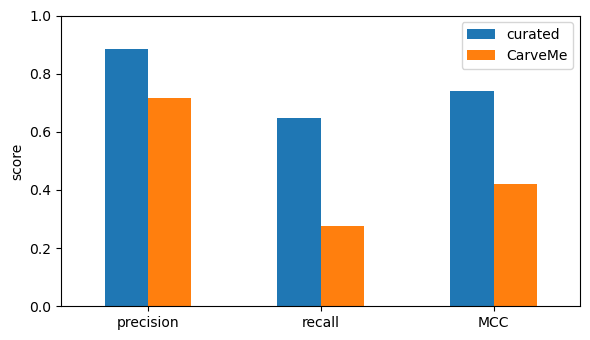

In [12]:
ax = performance[["precision", "recall", "MCC"]].T.plot.bar(rot=0, figsize=(6, 3.5))
ax.set_ylabel("score")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

Most of the CarveMe model's errors are false negatives: genes the cell cannot live without, but which the model predicts are dispensable. Possible reasons include redundancy that exists in the model but not in the cell (an alternative route, or a gene wrongly assigned as an isozyme, can compensate for a knockout *in silico* but not *in vivo*), and the model not needing the gene's product at all. Let us list some of the essential genes that only the curated model gets right:

In [13]:
both = predicted["curated"].index.intersection(predicted["CarveMe"].index) \
                                .intersection(observed_essential.index)
missed = [g for g in both if observed_essential[g] and predicted["curated"][g]
          and not predicted["CarveMe"][g]]
names = pec.set_index("locus")
names.loc[missed, ["Orf", "Product"]].head(15)

,Orf,Product
locus,,
b0029,ispH,4-hydroxy-3-methylbut-2-enyl diphosphate reduc...
b0084,ftsI,transpeptidase involved in septal peptidoglyca...
b0096,lpxC,UDP-3-O-acyl N-acetylglucosamine deacetylase
b0154,hemL,glutamate-1-semialdehyde aminotransferase (ami...
b0175,cdsA,CDP-diglyceride synthase
b0179,lpxD,UDP-3-O-(3-hydroxymyristoyl)-glucosamine N-acy...
b0181,lpxA,UDP-N-acetylglucosamine acetyltransferase
b0182,lpxB,tetraacyldisaccharide-1-P synthase
b0185,accA,"acetyl-CoA carboxylase, carboxytransferase, al..."


Most of these genes make components of the cell envelope (lipid A by the *lpx* genes, phospholipids, peptidoglycan) or cofactors such as heme (*hemB*, *hemL*). That pattern has a simple explanation, which we can see by comparing the two biomass reactions:

In [14]:
def biomass_components(reaction):
    return {m.id for m, coef in reaction.metabolites.items() if coef < 0}

only_curated = biomass_components(curated.reactions.BIOMASS_Ec_iML1515_core_75p37M) \
             - biomass_components(carved.reactions.Growth)
sorted(only_curated)

['2fe2s_c',
 '2ohph_c',
 '4fe4s_c',
 'btn_c',
 'kdo2lipid4_e',
 'mobd_c',
 'murein5px4p_p',
 'nh4_c',
 'ni2_c',
 'pe160_p',
 'pe161_p',
 'pheme_c',
 'sheme_c',
 'succoa_c',
 'udcpdp_c']

The biomass reaction of *i*ML1515 was compiled from measurements of *E. coli*'s cell composition, and it requires heme, lipid A (as part of `kdo2lipid4_e`), phospholipids (`pe160_p`, `pe161_p`) and peptidoglycan (`murein5px4p_p`). CarveMe uses a generic bacterial biomass reaction without these components. If the model does not need to make a compound, then a gene needed only to make that compound cannot be essential in the model. This is an example of a general point: the objective function is part of the model, and getting it right takes organism-specific knowledge.

## A look at less studied organisms

For *E. coli* we could check the automatic model against decades of experiments. For most bacteria there is nothing to check against, and the CarveMe model may be the only metabolic model available. Even so, it can produce testable predictions. As an example, we look at which amino acids a few organisms can make themselves. We pick two species with very small genomes, the aphid endosymbiont *Buchnera aphidicola* and the human pathogen *Mycoplasma genitalium*, and compare them with *E. coli*. A model is auxotrophic for an amino acid if it can grow on rich medium but no longer grows when that amino acid is removed.

In [15]:
organisms = {
    "E. coli": "e/escherichia/Escherichia_coli_str_K_12_substr_MG1655",
    "B. aphidicola": "b/buchnera/Buchnera_aphidicola_str_APS_Acyrthosiphon_pisum",
    "M. genitalium": "m/mycoplasma/Mycoplasma_genitalium_G37_G_37",
}
amino_acids = ["ala__L", "arg__L", "asn__L", "asp__L", "cys__L", "gln__L", "glu__L",
               "gly", "his__L", "ile__L", "leu__L", "lys__L", "met__L", "phe__L",
               "pro__L", "ser__L", "thr__L", "trp__L", "tyr__L", "val__L"]

rows = {}
for name, path in organisms.items():
    fname = path.split("/")[-1] + ".xml.gz"
    urls[fname] = embl_gems + path + ".xml.gz"
    model = cobra.io.read_sbml_model(fetch(fname))
    for ex in model.exchanges:
        ex.lower_bound = -10.0
    wild_type = model.slim_optimize()
    auxotrophies = []
    for aa in amino_acids:
        ex_id = f"EX_{aa}_e"
        if ex_id in model.reactions:  # without an uptake reaction it must be synthesized
            with model:
                model.reactions.get_by_id(ex_id).lower_bound = 0.0
                if model.slim_optimize(error_value=0.0) < 0.01 * wild_type:
                    auxotrophies.append(aa.split("__")[0])
    rows[name] = {"genes": len(model.genes), "reactions": len(model.reactions),
                  "auxotrophic for": ", ".join(auxotrophies) or "-"}

pd.set_option("display.max_colwidth", None)
pd.DataFrame(rows).T

,genes,reactions,auxotrophic for
E. coli,1554,2759,-
B. aphidicola,246,1233,"asn, asp, gln, tyr, val"
M. genitalium,90,533,"arg, gln, his, ile, leu, lys, met, phe, pro, thr, trp, val"


The results match what is known about these organisms' lifestyles. *E. coli* makes all twenty amino acids itself. *Mycoplasma genitalium* has one of the smallest genomes of any organism that can be grown in pure culture, and as a parasite it takes nearly everything from its host, so its model needs most of the amino acids supplied. *Buchnera* is a more interesting case. Its genome shows that the endosymbiont has kept the pathways for the amino acids that are *essential* to its aphid host, which feeds on phloem sap that is poor in them, while it imports several non-essential ones from the host ([Shigenobu et al. 2000](https://doi.org/10.1038/35024074)). Four of the five auxotrophies the model predicts are for amino acids that animals can make themselves (asparagine, aspartate, glutamine and tyrosine), so the model largely reproduces this pattern. The exception is valine. Each prediction is also a hypothesis that could be tested experimentally, or checked against more careful curation of these pathways.

This kind of model is also the starting point for the omics integration we discussed in the previous chapter. If a model of an organism exists, even an automatically built one, then transcriptomics, proteomics or metagenomics data for that organism can be mapped onto its reactions through the GPR rules. CarveMe models are used this way in community modeling of the gut microbiome, where most species have no curated model.

## Discussion Questions

1. The CarveMe model could not grow anaerobically because a single gene-less reaction was missing. Should curated models contain reactions without genetic evidence? What are the risks of adding them, and how could you test whether such a reaction really exists?
2. We approximated LB medium by allowing uptake of every compound the model has an exchange reaction for. How might this choice bias the essentiality predictions? Which kinds of genes would you expect to be wrongly predicted as non-essential in rich medium but essential in minimal medium?
3. Both models were evaluated only on the genes they contain, and they contain different genes. Why does this make a direct comparison of their accuracies difficult? How would you set up a fairer comparison?
4. Suppose you have the genome of a newly isolated soil bacterium and a list of the carbon sources it can grow on. How would you use this information when building and validating a CarveMe model?
5. The *Buchnera* model is auxotrophic for valine, an amino acid that is essential for the aphid. Is this a model error, or could it reflect real biology? What would you look for in the genome annotation and in the literature to decide?

:::{dropdown} What you should know after reading this chapter
You should be able to:
1. Contrast bottom-up curated reconstruction of a GEM (such as *i*ML1515) with top-down automatic reconstruction (CarveMe), and explain why a curated model can contain knowledge that is not in the genome, such as a reaction without an associated gene.
2. Judge a model's essentiality predictions against knockout data using a confusion matrix, precision, recall and the Matthews correlation coefficient (MCC). Explain why accuracy is misleading when only a small fraction of the genes are essential.
3. Explain why a gene needed only to make a compound that is absent from the biomass reaction cannot be predicted as essential, and hence why the objective function is part of the model.
4. Describe how a growth medium is set through the uptake bounds of exchange reactions, and how removing a single amino acid from the medium predicts an auxotrophy.
:::